In [4]:
import numpy as np
import matplotlib.pyplot as plt
import estraces
import os

In [5]:
# S-BOX
sbox = (
    0x63, 0x7c, 0x77, 0x7b, 0xf2, 0x6b, 0x6f, 0xc5, 0x30, 0x01, 0x67, 0x2b, 0xfe, 0xd7, 0xab, 0x76,
    0xca, 0x82, 0xc9, 0x7d, 0xfa, 0x59, 0x47, 0xf0, 0xad, 0xd4, 0xa2, 0xaf, 0x9c, 0xa4, 0x72, 0xc0,
    0xb7, 0xfd, 0x93, 0x26, 0x36, 0x3f, 0xf7, 0xcc, 0x34, 0xa5, 0xe5, 0xf1, 0x71, 0xd8, 0x31, 0x15,
    0x04, 0xc7, 0x23, 0xc3, 0x18, 0x96, 0x05, 0x9a, 0x07, 0x12, 0x80, 0xe2, 0xeb, 0x27, 0xb2, 0x75,
    0x09, 0x83, 0x2c, 0x1a, 0x1b, 0x6e, 0x5a, 0xa0, 0x52, 0x3b, 0xd6, 0xb3, 0x29, 0xe3, 0x2f, 0x84,
    0x53, 0xd1, 0x00, 0xed, 0x20, 0xfc, 0xb1, 0x5b, 0x6a, 0xcb, 0xbe, 0x39, 0x4a, 0x4c, 0x58, 0xcf,
    0xd0, 0xef, 0xaa, 0xfb, 0x43, 0x4d, 0x33, 0x85, 0x45, 0xf9, 0x02, 0x7f, 0x50, 0x3c, 0x9f, 0xa8,
    0x51, 0xa3, 0x40, 0x8f, 0x92, 0x9d, 0x38, 0xf5, 0xbc, 0xb6, 0xda, 0x21, 0x10, 0xff, 0xf3, 0xd2,
    0xcd, 0x0c, 0x13, 0xec, 0x5f, 0x97, 0x44, 0x17, 0xc4, 0xa7, 0x7e, 0x3d, 0x64, 0x5d, 0x19, 0x73,
    0x60, 0x81, 0x4f, 0xdc, 0x22, 0x2a, 0x90, 0x88, 0x46, 0xee, 0xb8, 0x14, 0xde, 0x5e, 0x0b, 0xdb,
    0xe0, 0x32, 0x3a, 0x0a, 0x49, 0x06, 0x24, 0x5c, 0xc2, 0xd3, 0xac, 0x62, 0x91, 0x95, 0xe4, 0x79,
    0xe7, 0xc8, 0x37, 0x6d, 0x8d, 0xd5, 0x4e, 0xa9, 0x6c, 0x56, 0xf4, 0xea, 0x65, 0x7a, 0xae, 0x08,
    0xba, 0x78, 0x25, 0x2e, 0x1c, 0xa6, 0xb4, 0xc6, 0xe8, 0xdd, 0x74, 0x1f, 0x4b, 0xbd, 0x8b, 0x8a,
    0x70, 0x3e, 0xb5, 0x66, 0x48, 0x03, 0xf6, 0x0e, 0x61, 0x35, 0x57, 0xb9, 0x86, 0xc1, 0x1d, 0x9e,
    0xe1, 0xf8, 0x98, 0x11, 0x69, 0xd9, 0x8e, 0x94, 0x9b, 0x1e, 0x87, 0xe9, 0xce, 0x55, 0x28, 0xdf,
    0x8c, 0xa1, 0x89, 0x0d, 0xbf, 0xe6, 0x42, 0x68, 0x41, 0x99, 0x2d, 0x0f, 0xb0, 0x54, 0xbb, 0x16)

# correct key
ckeys = (
    0xa0, 0x0b, 0x09, 0x17, 0x04, 0x01, 0xd4, 0xc7, 0x28, 0x39, 0xaa, 0x6b, 0xcc, 0x0d, 0x04, 0x0e)


In [6]:
# Byte substitution
def sub_bytes(pt, keyguess):
    return sbox[pt ^ keyguess]

# Create a folder for saving images
image_folder = 'images'
os.makedirs(image_folder, exist_ok=True)

In [7]:
num_of_traces = int(input("Enter the number of traces to analyze: "))
# aes200 traces and plaintexts 
# download from https://4007268444.share.123pan.cn/123pan/TOHmwh-S4lAd
traces = np.load('traceAES200.npy').astype(float)
traces = traces[:num_of_traces, :]
pt = np.load('plaintextAES200.npy')
pt = pt[:num_of_traces, :]
trace_cnt = np.shape(traces)[0]
points_cnt = np.shape(traces)[1]
print("Number of traces: ", trace_cnt)
print(pt.shape,traces.shape)

Number of traces:  100
(100, 16) (100, 7738)


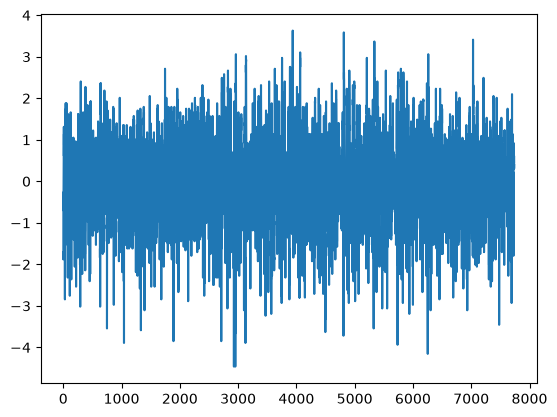

In [9]:
plt.plot(traces[1]); 
plt.show()

In [10]:
traces = traces.T

# Hamming weight
HW = []
for n in range(0, 256):
    HW.append(bin(n).count("1"))


Byte 16

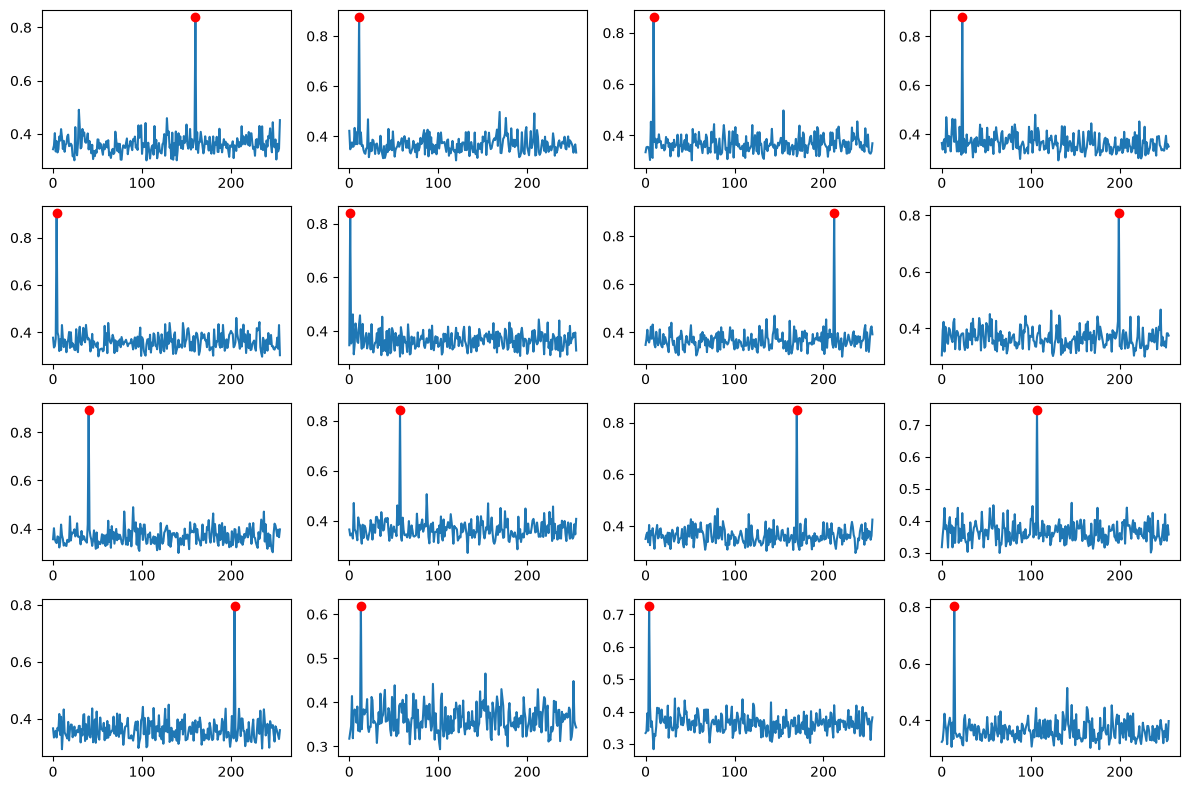

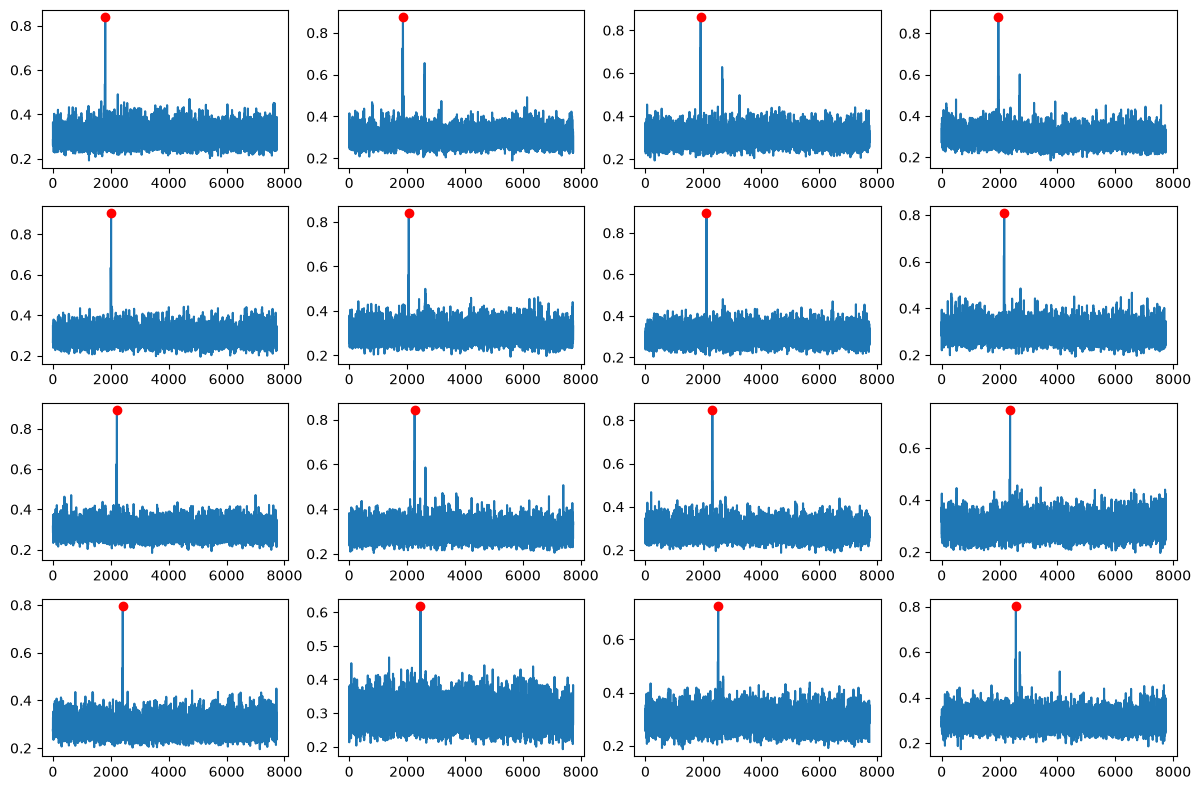

In [11]:
keys = []

kguesses = np.arange(256)
kguesses = np.tile(kguesses, (trace_cnt, 1))  # Expand to trace_cnt rows and 256 columns

fig1, axes1 = plt.subplots(nrows=4, ncols=4, figsize=(12, 8))  # Create a 4x4 grid of subplots
fig2, axes2 = plt.subplots(nrows=4, ncols=4, figsize=(12, 8))  # Create a 4x4 grid of subplots
# Attack each byte
for pi in range(0, 16):
    print("\rByte %d" % (pi + 1), end="")
    cpa_data = []  # Store correlation coefficients for each guess
    
    pt_col = [row[pi] for row in pt]
    pt_col = np.array(pt_col)  # Convert the plaintext column to a NumPy array
    pt_col = np.tile(pt_col, (256, 1)).T  # Expand the plaintext column to 256 rows and trace_cnt columns
    pt_col = np.reshape(pt_col, (trace_cnt, 256))  # Reshape to trace_cnt rows and 256 columns
    vectorized_sub_bytes = np.vectorize(sub_bytes)  # Vectorize the sub_bytes function
    pt_col = vectorized_sub_bytes(pt_col, kguesses)  # Apply byte substitution to the plaintext column
    hyp = np.array([[HW[val] for val in row] for row in pt_col])  # Calculate the Hamming weight of each byte
    #print(hyp)  # Print the current plaintext column
    #print(hyp.shape)  # Print the shape of the current plaintext column
    #print(traces.shape)  # Print the shape of the power traces

    rho = np.corrcoef(traces, hyp.T)[:traces.shape[0], traces.shape[0]:]  # Calculate correlations between traces and hypotheses
    #print(rho.shape) 
    rho = np.abs(rho)  # Take absolute values
    maxrho1 = np.max(rho, axis=0)  # Find the maximum correlation for each key guess
    maxrho2 = np.max(rho.T, axis=0)  # Find the maximum correlation for each sample point

    keys.append(np.argmax(maxrho1))  # Find the key guess with the maximum correlation

    axes1[pi // 4, pi % 4].plot(maxrho1)  # Plot the correlation coefficients
    axes1[pi // 4, pi % 4].scatter(ckeys[pi], maxrho1[ckeys[pi]], color='red', zorder=3)
    axes2[pi // 4, pi % 4].plot(maxrho2)  # Plot the correlation coefficients
    correct_key_sample = np.argmax(rho[:, ckeys[pi]])
    axes2[pi // 4, pi % 4].scatter(correct_key_sample, rho[correct_key_sample, ckeys[pi]], color='red', zorder=3)


fig1.tight_layout()
fig2.tight_layout()
plt.show()


In [12]:
def display_key_analysis(recovered_keys, correct_keys):
    """
    Compare the recovered key with the correct key and display any differences.
    :param recovered_keys: Key recovered by the attacker (bytes or a list of integers)
    :param correct_keys: The correct key (bytes or a list of integers)
    """
    print("\n" + "=" * 65)
    print(f"{'Key Byte Analysis':^60}")
    print("=" * 65)
    
    # Print the table header
    # Format: index | recovered value | status | correct value
    print(f"{'Idx':<6} | {'Recovered':<12} | {'Status':<8} | {'Correct':<12}")
    print("-" * 65)

    correct_count = 0
    
    # Compare each byte of the key
    for i in range(len(correct_keys)):
        rec_byte = recovered_keys[i] if i < len(recovered_keys) else None
        cor_byte = correct_keys[i]
        
        # Format as hexadecimal (for example: 0xa0)
        rec_str = f"0x{rec_byte:02x}" if rec_byte is not None else "None"
        cor_str = f"0x{cor_byte:02x}"
        
        # Check whether the bytes match
        if rec_byte == cor_byte:
            status = "✅ Match"
            correct_count += 1
        else:
            status = "❌ Error"
            
        print(f"{i:<6} | {rec_str:<12} | {status:<8} | {cor_str:<12}")

    print("-" * 65)
    
    # Calculate the success rate
    total = len(correct_keys)
    accuracy = (correct_count / total) * 100 if total > 0 else 0
    
    print(f"\n📊 Summary:")
    print(f"   Total bytes: {total}")
    print(f"   Correct matches: {correct_count}")
    print(f"   Attack accuracy: {accuracy:.1f}%")
    
    if accuracy == 100.0:
        print("   🎉 Congratulations! All subkeys were recovered successfully!")
    else:
        print("   ⚠️ Some keys were not recovered or are incorrect.")
    print("=" * 65 + "\n")

In [13]:
# Print the recovered key
print("The recovered Key is: ", )
for b in keys:
    print("%02x " % b, end="") 

The recovered Key is: 
a0 0b 09 17 04 01 d4 c7 28 39 aa 6b cc 0d 04 0e 

In [14]:
# Print the correct key
print("\nThe correct Key is: ", )
for b in ckeys:
    print("%02x " % b, end="")


The correct Key is: 
a0 0b 09 17 04 01 d4 c7 28 39 aa 6b cc 0d 04 0e 

In [15]:
display_key_analysis(keys, ckeys)


                     Key Byte Analysis                      
Idx    | Recovered    | Status   | Correct     
-----------------------------------------------------------------
0      | 0xa0         | ✅ Match  | 0xa0        
1      | 0x0b         | ✅ Match  | 0x0b        
2      | 0x09         | ✅ Match  | 0x09        
3      | 0x17         | ✅ Match  | 0x17        
4      | 0x04         | ✅ Match  | 0x04        
5      | 0x01         | ✅ Match  | 0x01        
6      | 0xd4         | ✅ Match  | 0xd4        
7      | 0xc7         | ✅ Match  | 0xc7        
8      | 0x28         | ✅ Match  | 0x28        
9      | 0x39         | ✅ Match  | 0x39        
10     | 0xaa         | ✅ Match  | 0xaa        
11     | 0x6b         | ✅ Match  | 0x6b        
12     | 0xcc         | ✅ Match  | 0xcc        
13     | 0x0d         | ✅ Match  | 0x0d        
14     | 0x04         | ✅ Match  | 0x04        
15     | 0x0e         | ✅ Match  | 0x0e        
--------------------------------------------------------